# PSD Basics for Mouse EEG

This notebook is a more **EEG-focused** introduction to PSD computation and analysis.

It is designed to teach someone the basics using examples that are closer to **mouse EEG workflows**.

Topics covered:
- why PSDs are useful for EEG
- how to compute PSDs with Welch's method
- how frequency resolution depends on window length
- how to compare PSDs across conditions
- how to compute band power
- how preprocessing choices can matter


## 1. Why PSDs are useful for EEG

EEG signals contain activity at many frequencies at once.

A PSD helps answer questions like:
- Is there strong low-frequency activity?
- Is there elevated gamma power?
- Is there a narrow noise peak near 60 Hz?
- Does one condition have more power in a certain band than another?

For mouse EEG, PSDs are often used to compare:
- genotypes
- treatment groups
- vigilance states such as wake, NREM, and REM
- time points in longitudinal studies


## 2. Imports


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal


## 3. Simulate a mouse EEG-like signal

This is still a toy example, but it is a little closer to EEG than the first notebook.

We will combine:
- slow activity around 3 Hz
- theta-like activity around 7 Hz
- gamma-like activity around 40 Hz
- noise
- a small 60 Hz contamination term

This is not meant to be a perfect physiological model. It is just a teaching signal.

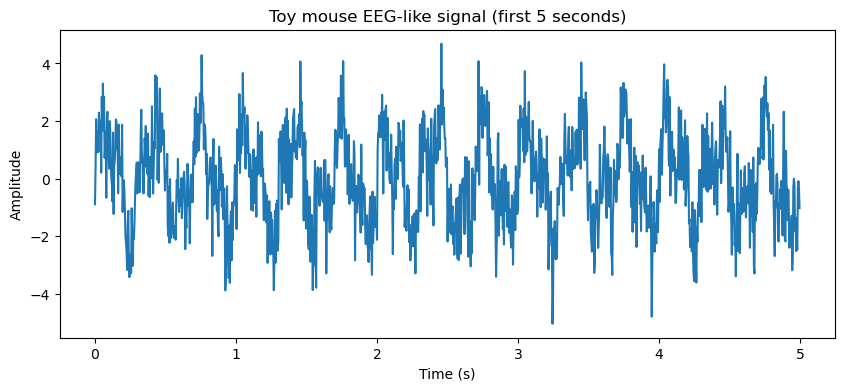

In [2]:
fs = 250
duration = 60  # seconds
t = np.arange(0, duration, 1 / fs)
rng = np.random.default_rng(123)

delta = 1.5 * np.sin(2 * np.pi * 3 * t)
theta = 1.0 * np.sin(2 * np.pi * 7 * t)
gamma = 0.35 * np.sin(2 * np.pi * 40 * t)
line_noise = 0.15 * np.sin(2 * np.pi * 60 * t)
noise = 0.9 * rng.normal(size=len(t))

x = delta + theta + gamma + line_noise + noise

plt.figure(figsize=(10, 4))
plt.plot(t[:1250], x[:1250])
plt.xlabel('Time (s)')
plt.ylabel('Amplitude')
plt.title('Toy mouse EEG-like signal (first 5 seconds)')
plt.show()

## 4. Compute the PSD with Welch's method

Welch's method is often the default starting point because it is simple and robust.

We will use:
- `fs = 250 Hz`
- 4-second windows
- 50% overlap


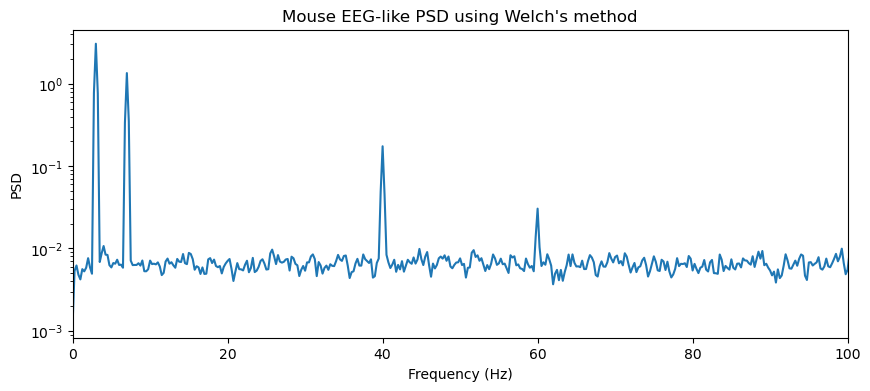

In [3]:
nperseg = fs * 4
noverlap = nperseg // 2

freqs, psd = signal.welch(
    x,
    fs=fs,
    nperseg=nperseg,
    noverlap=noverlap,
    scaling='density'
)

plt.figure(figsize=(10, 4))
plt.semilogy(freqs, psd)
plt.xlim(0, 100)
plt.xlabel('Frequency (Hz)')
plt.ylabel('PSD')
plt.title("Mouse EEG-like PSD using Welch's method")
plt.show()

## 5. Focus on the frequency range of interest

For EEG, it is common to zoom into a biologically relevant range.

For example, here we look at 1-80 Hz.

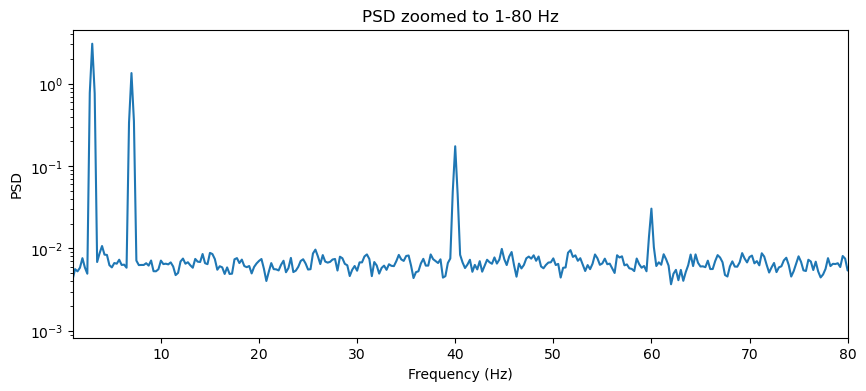

In [4]:
plt.figure(figsize=(10, 4))
plt.semilogy(freqs, psd)
plt.xlim(1, 80)
plt.xlabel('Frequency (Hz)')
plt.ylabel('PSD')
plt.title('PSD zoomed to 1-80 Hz')
plt.show()

## 6. Frequency resolution

A useful approximation is:

`resolution ~= fs / nperseg`

With 4-second windows at 250 Hz:
- `nperseg = 1000`
- resolution is about `250 / 1000 = 0.25 Hz`

That means nearby frequencies are sampled about every 0.25 Hz.

In [5]:
resolution = fs / nperseg
print(f'Approximate frequency resolution: {resolution:.3f} Hz')

Approximate frequency resolution: 0.250 Hz


## 7. Compare different window lengths

Longer windows improve frequency resolution.
Shorter windows usually give smoother estimates but less precise frequency localization.

This is one of the main practical tradeoffs in PSD work.

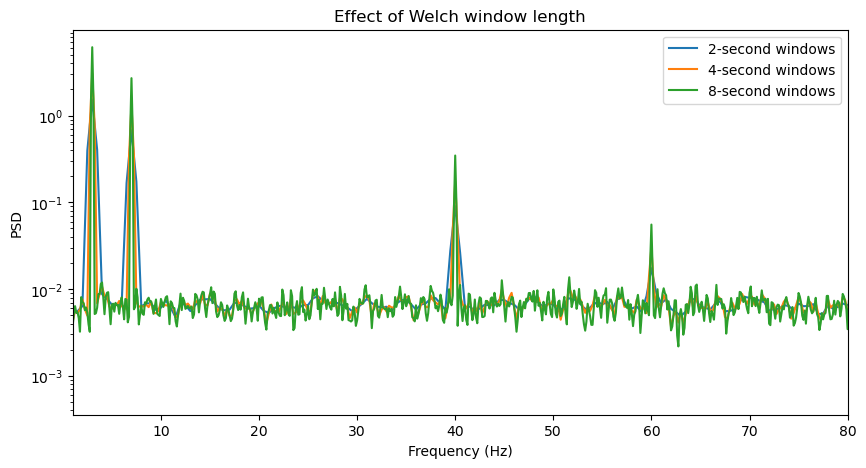

In [6]:
window_seconds = [2, 4, 8]

plt.figure(figsize=(10, 5))
for sec in window_seconds:
    nps = fs * sec
    f, p = signal.welch(x, fs=fs, nperseg=nps, noverlap=nps // 2)
    plt.semilogy(f, p, label=f'{sec}-second windows')

plt.xlim(1, 80)
plt.xlabel('Frequency (Hz)')
plt.ylabel('PSD')
plt.title('Effect of Welch window length')
plt.legend()
plt.show()

## 8. Band power helper

A common next step is to summarize the PSD in predefined frequency bands.

These exact bands vary by species and project, but this gives the basic idea.

In [7]:
def bandpower(freqs, psd, fmin, fmax):
    mask = (freqs >= fmin) & (freqs <= fmax)
    return np.trapz(psd[mask], freqs[mask])

bands = {
    'delta_1_4': (1, 4),
    'theta_4_8': (4, 8),
    'alpha_8_12': (8, 12),
    'beta_12_30': (12, 30),
    'gamma_30_70': (30, 70),
}

for name, (fmin, fmax) in bands.items():
    bp = bandpower(freqs, psd, fmin, fmax)
    print(f'{name}: {bp:.4f}')

delta_1_4: 1.1661
theta_4_8: 0.5319
alpha_8_12: 0.0246
beta_12_30: 0.1174
gamma_30_70: 0.3356


## 9. Visualize the bands on the PSD

This makes it easier to connect the numeric summaries back to the spectrum.

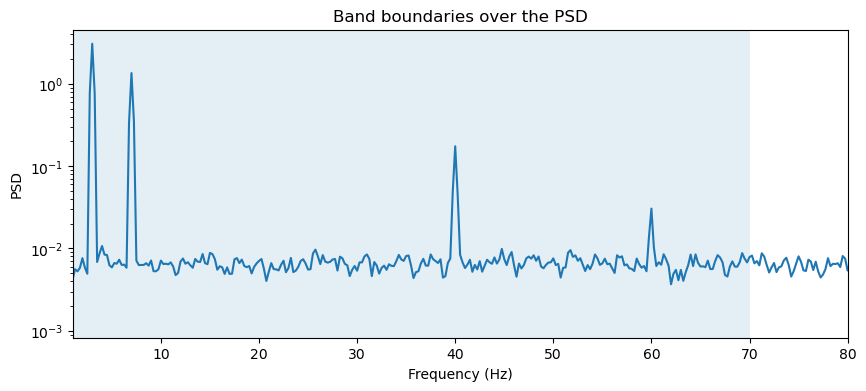

In [8]:
plt.figure(figsize=(10, 4))
plt.semilogy(freqs, psd)

for label, (fmin, fmax) in bands.items():
    plt.axvspan(fmin, fmax, alpha=0.12)

plt.xlim(1, 80)
plt.xlabel('Frequency (Hz)')
plt.ylabel('PSD')
plt.title('Band boundaries over the PSD')
plt.show()

## 10. Absolute and relative band power

Absolute power is the raw integrated power in a band.

Relative power divides by total power across a reference range.
That can be useful when you care about the fraction of total power in a band.

In [ ]:
total_power_1_80 = bandpower(freqs, psd, 1, 80)

for name, (fmin, fmax) in bands.items():
    abs_bp = bandpower(freqs, psd, fmin, fmax)
    rel_bp = abs_bp / total_power_1_80
    print(f'{name}: absolute={abs_bp:.4f}, relative={rel_bp:.3f}')

## 11. Comparing two conditions

Now let's simulate a second condition with **lower gamma power**.

This is a common kind of biological comparison: one group or condition may have less power in a frequency range of interest.

In [ ]:
gamma_low = 0.15 * np.sin(2 * np.pi * 40 * t)
x_low_gamma = delta + theta + gamma_low + line_noise + noise

f_a, p_a = signal.welch(x, fs=fs, nperseg=nperseg, noverlap=noverlap)
f_b, p_b = signal.welch(x_low_gamma, fs=fs, nperseg=nperseg, noverlap=noverlap)

plt.figure(figsize=(10, 4))
plt.semilogy(f_a, p_a, label='Condition A')
plt.semilogy(f_b, p_b, label='Condition B')
plt.xlim(1, 80)
plt.xlabel('Frequency (Hz)')
plt.ylabel('PSD')
plt.title('Two conditions with different gamma power')
plt.legend()
plt.show()

## 12. Quantify the gamma-band difference

Plotting gives intuition, but often we also want a simple numeric comparison.

In [ ]:
gamma_a = bandpower(f_a, p_a, 30, 70)
gamma_b = bandpower(f_b, p_b, 30, 70)

print(f'Condition A gamma power: {gamma_a:.4f}')
print(f'Condition B gamma power: {gamma_b:.4f}')
print(f'Difference (A - B): {gamma_a - gamma_b:.4f}')

## 13. Why averaging matters

Single PSD estimates can be noisy.

In real analysis, people often average across:
- epochs
- channels
- animals
- time windows within a state

Averaging reduces noise and makes stable group patterns easier to see.

In [ ]:
def simulate_condition(gamma_amp, seed):
    local_rng = np.random.default_rng(seed)
    noise_local = 0.9 * local_rng.normal(size=len(t))
    x_local = delta + theta + gamma_amp * np.sin(2 * np.pi * 40 * t) + line_noise + noise_local
    f, p = signal.welch(x_local, fs=fs, nperseg=nperseg, noverlap=noverlap)
    return f, p

psds_a = []
psds_b = []

for seed in range(10):
    _, p1 = simulate_condition(0.35, seed)
    _, p2 = simulate_condition(0.15, seed + 100)
    psds_a.append(p1)
    psds_b.append(p2)

psds_a = np.array(psds_a)
psds_b = np.array(psds_b)

mean_a = psds_a.mean(axis=0)
mean_b = psds_b.mean(axis=0)

plt.figure(figsize=(10, 4))
plt.semilogy(f_a, mean_a, label='Condition A mean PSD')
plt.semilogy(f_b, mean_b, label='Condition B mean PSD')
plt.xlim(1, 80)
plt.xlabel('Frequency (Hz)')
plt.ylabel('PSD')
plt.title('Averaged PSDs across simulated recordings')
plt.legend()
plt.show()

## 14. Simple log-transform view

It is also common to log-transform spectra before plotting or modeling.

That can compress the range and make differences easier to inspect.

In [ ]:
eps = 1e-12

plt.figure(figsize=(10, 4))
plt.plot(f_a, np.log10(mean_a + eps), label='Condition A')
plt.plot(f_b, np.log10(mean_b + eps), label='Condition B')
plt.xlim(1, 80)
plt.xlabel('Frequency (Hz)')
plt.ylabel('log10(PSD)')
plt.title('Mean PSDs on a log10 scale')
plt.legend()
plt.show()

## 15. A reusable PSD helper

Wrapping your spectral settings in a function makes your analysis more consistent.

In [ ]:
def compute_psd_welch(x, fs, win_sec=4, overlap_frac=0.5):
    nperseg = int(fs * win_sec)
    noverlap = int(nperseg * overlap_frac)
    freqs, psd = signal.welch(
        x,
        fs=fs,
        nperseg=nperseg,
        noverlap=noverlap,
        scaling='density'
    )
    return freqs, psd

freqs_demo, psd_demo = compute_psd_welch(x, fs, win_sec=4)
print(freqs_demo[:6])
print(psd_demo[:6])

## 16. Practical issues to discuss with a learner

If you are teaching someone the basics, these are good questions to ask:

1. What happens if we shorten the window?
2. What happens if noise increases?
3. What happens if there is strong 60 Hz contamination?
4. What happens if one condition differs only in gamma power?
5. When should we use absolute versus relative power?

These questions help connect the PSD from a plotting object to a real analysis tool.

## 17. Small exercise section

Try changing these values and rerunning cells:

- make the gamma amplitude larger or smaller
- remove the 60 Hz noise term
- change the window from 4 seconds to 2 or 8 seconds
- increase the broadband noise level
- compare 30-70 Hz gamma power between conditions again

Good follow-up questions:
- Which differences are easiest to see visually?
- Which differences are clearer in band-power summaries?
- How does the PSD change when only noise changes?


## 18. Key takeaways

- PSDs are a core tool for analyzing EEG frequency content.
- Welch's method is a strong default for teaching and routine analysis.
- Window length affects the tradeoff between smoothness and frequency resolution.
- Band power turns spectra into interpretable summaries.
- Group differences can often be seen both in the PSD shape and in band-power numbers.
- Real EEG analysis depends strongly on artifact handling and preprocessing choices.


## 19. Where to go next

A natural next notebook would add:
- state-specific PSDs for wake, NREM, and REM
- multiple simulated animals per group
- confidence intervals or standard errors across animals
- normalized PSDs
- flattening / parameterization of spectra

That would make the examples even closer to a real mouse EEG pipeline.